# Milestone 2 — SVD and Rank-k Approximation

Compute the SVD and compare reconstructions of different ranks.

In [1]:

import os

if not os.path.exists("/content/svd-image-compression"):
    !git clone -q https://github.com/billygoattrain/svd-image-compression.git /content/svd-image-compression

%cd /content/svd-image-compression


/content/svd-image-compression


In [2]:
import sys, pathlib
from skimage import data
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# Works after downloading/extracting the package, or from the project root in Colab.
project_root = pathlib.Path.cwd()
if not (project_root / "src").exists() and (project_root.parent / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from compress import rank_k_approx, storage, compression_ratio, rel_error, predicted_error, k_for_error
(project_root / "figures").mkdir(exist_ok=True)
photo_path = project_root / "data" / "my_photo.png"
if photo_path.exists():
    P = np.array(Image.open(photo_path).convert("L"), dtype=float)
else:
    P = None
    print("Personal photograph not found; please add data/my_photo.png.")

## SVD check

In [3]:
A=data.camera().astype(float)
U,s,Vt=np.linalg.svd(A,full_matrices=False)
print(U.shape,s.shape,Vt.shape)
print("Reconstruction close:",np.allclose((U*s)@Vt,A))
print("First singular values:",np.round(s[:5],1))

(512, 512) (512,) (512, 512)
Reconstruction close: True
First singular values: [70966.  17054.6 13314.9  8837.4  5874.6]


The SVD factors reconstruct the original image; the leading singular values dominate its energy.

## Singular values plot

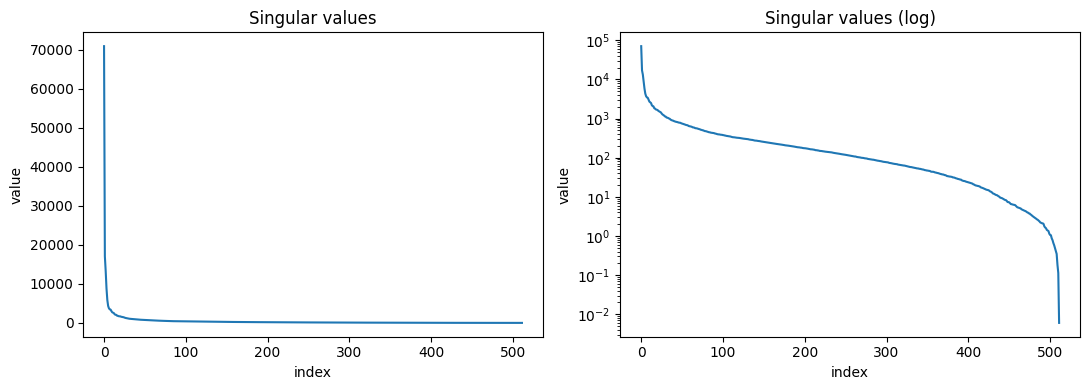

In [4]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(s);axs[0].set(title="Singular values",xlabel="index",ylabel="value")
axs[1].semilogy(s);axs[1].set(title="Singular values (log)",xlabel="index",ylabel="value")
plt.tight_layout();plt.show()

The logarithmic scale reveals small singular values.

## Compare ranks

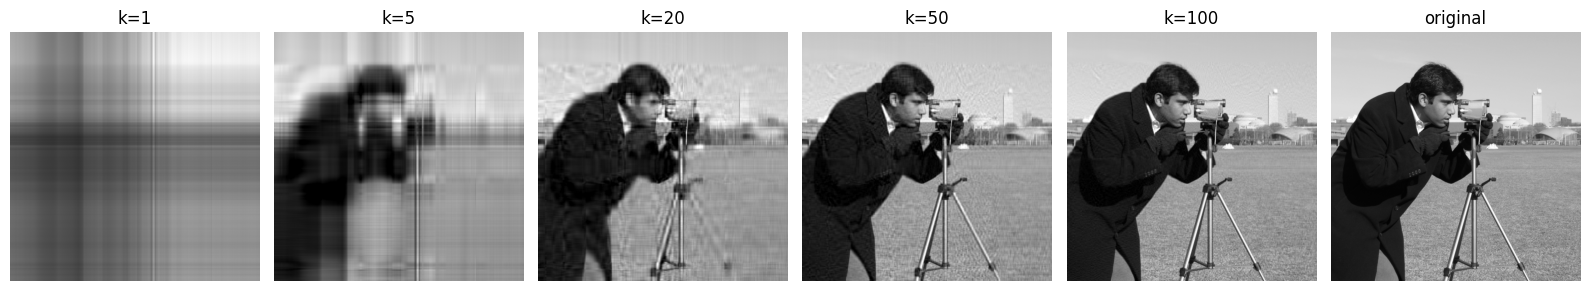

In [5]:
ks=[1,5,20,50,100]
fig,axs=plt.subplots(1,len(ks)+1,figsize=(16,3))
for ax,k in zip(axs,ks):
    ax.imshow(np.clip(rank_k_approx(A,k),0,255),cmap="gray",vmin=0,vmax=255)
    ax.set_title(f"k={k}");ax.axis("off")
axs[-1].imshow(A,cmap="gray",vmin=0,vmax=255);axs[-1].set_title("original");axs[-1].axis("off");plt.tight_layout();plt.show()

Smaller k uses fewer singular vectors but loses detail.

## Exact SVD reconstruction and singular-value diagnostics

SVD represents a matrix as `U @ diag(s) @ Vt`. Any difference after reconstructing the image should be tiny floating-point roundoff.

In [6]:
A_back=U @ np.diag(s) @ Vt
print("Image shape, dtype:",A.shape,A.dtype)
print("U, s, Vt shapes:",U.shape,s.shape,Vt.shape)
print("Rebuilt correctly?",np.allclose(A,A_back))
print("Maximum absolute reconstruction error:",np.abs(A-A_back).max())
print("First five:",np.round(s[:5],1))
print("50th, 200th, last:",round(s[49],1),round(s[199],1),round(s[-1],3))

Image shape, dtype: (512, 512) float64
U, s, Vt shapes: (512, 512) (512,) (512, 512)
Rebuilt correctly? True
Maximum absolute reconstruction error: 2.503952600818593e-11
First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


## Rank and full reconstruction checks

A rank-10 truncated SVD has rank 10 (within numerical tolerance). Keeping all 512 singular components reconstructs the original camera matrix. The stripe image has only one nonzero singular value.

In [7]:
A10=rank_k_approx(A,10)
print("Rank of A10:",np.linalg.matrix_rank(A10))
print("Full rank-512 reconstruction correct?",np.allclose(rank_k_approx(A,512),A))
stripes2=np.outer([1,0,1,0],[1,1,1,1]).astype(float)
print("Stripe singular values:",np.round(np.linalg.svd(stripes2,compute_uv=False),4))

Rank of A10: 10
Full rank-512 reconstruction correct? True
Stripe singular values: [2.8284 0.     0.     0.    ]


## Exercise 1 — Singular values of a 2×2 matrix

For `M = [[3,0],[4,5]]`, we get `M.T @ M = [[25,20],[20,25]]`. Its eigenvalues are 45 and 5, so the singular values are `sqrt(45)` and `sqrt(5)`. Flipping the signs of both `u₁` and `v₁` leaves their outer product unchanged because `(-u₁)(-v₁)ᵀ = u₁v₁ᵀ`.

In [8]:
M=np.array([[3.,0.],[4.,5.]])
Mtm=M.T@M
evals=np.linalg.eigvalsh(Mtm)
computed=np.linalg.svd(M,compute_uv=False)
print("M.T @ M:\n",Mtm)
print("Eigenvalues (ascending):",evals)
print("Singular values from sqrt(eigenvalues):",np.sqrt(evals[::-1]))
print("NumPy singular values:",computed)
print("Same singular values?",np.allclose(np.sqrt(evals[::-1]),computed))
Um,sm,Vtm=np.linalg.svd(M,full_matrices=False)
print("Both signs flipped give the same rank-1 term?",np.allclose(np.outer(-Um[:,0],-Vtm[0,:]),np.outer(Um[:,0],Vtm[0,:])))

M.T @ M:
 [[25. 20.]
 [20. 25.]]
Eigenvalues (ascending): [ 5. 45.]
Singular values from sqrt(eigenvalues): [6.70820393 2.23606798]
NumPy singular values: [6.70820393 2.23606798]
Same singular values? True
Both signs flipped give the same rank-1 term? True


## Exercise 2 — Eckart–Young verification for camera at k=20

The approximation retains the first 20 singular values, which are indices 0 through 19 in Python. The discarded singular values therefore begin at `s[20:]`. Their squared sum predicts the optimal Frobenius reconstruction error.

In [9]:
k=20
measured=np.linalg.norm(A-rank_k_approx(A,k))
from_discarded=np.sqrt(np.sum(s[k:]**2))
print("Measured absolute Frobenius error:",measured)
print("Predicted absolute Frobenius error:",from_discarded)
print("Agreement:",np.isclose(measured,from_discarded))

Measured absolute Frobenius error: 7699.9091419681245
Predicted absolute Frobenius error: 7699.9091419681245
Agreement: True


## Exercise 3 — SVD on my photograph

The photo's singular-value distribution differs from the sample camera image because its shapes, lighting, and detail are different. Comparing several ranks helps me choose the smallest rank that still looks recognizable; this is a subjective visual criterion, not the same as the 10% Frobenius-error threshold.

Photo shape: (800, 600)
First five singular values: [99754.1 13223.6 10456.8  9199.9  6411.5]
Rank meeting <=10% error: 17


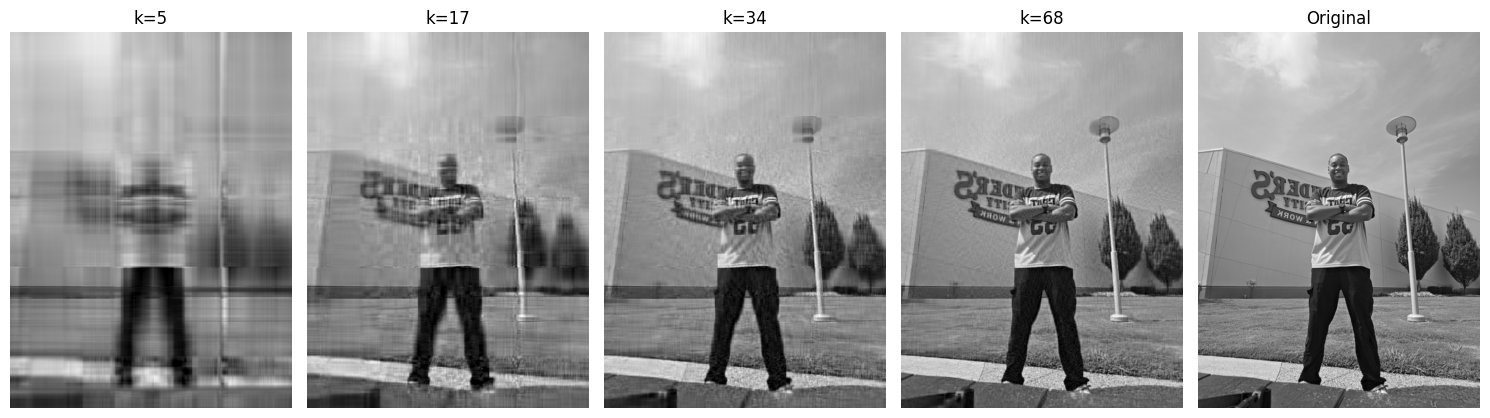

In [10]:
assert P is not None,"Add data/my_photo.png to run the personal-photo experiment."
photo_s=np.linalg.svd(P,compute_uv=False)
print("Photo shape:",P.shape)
print("First five singular values:",np.round(photo_s[:5],1))
print("Rank meeting <=10% error:",k_for_error(photo_s,0.10))
photo_ranks=[5,17,34,68]
fig,axes=plt.subplots(1,len(photo_ranks)+1,figsize=(15,5))
for ax,k in zip(axes,photo_ranks):
    ax.imshow(np.clip(rank_k_approx(P,k),0,255),cmap="gray",vmin=0,vmax=255)
    ax.set_title(f"k={k}");ax.axis("off")
axes[-1].imshow(P,cmap="gray",vmin=0,vmax=255)
axes[-1].set_title("Original");axes[-1].axis("off")
plt.tight_layout();plt.show()

**My interpretation to finalize:** At rank 17, the person's outline is recognizable but fine facial details and lettering are blurry. A higher rank such as 34 or 68 may be better if recognizable details matter. I should choose a rank after comparing the displayed results and explain the decision in my own words.

### What we found

The singular value decomposition successfully reconstructed the original 512 × 512 grayscale image, with Python confirming that the reconstruction was accurate. The largest singular value was approximately 70,966, which was significantly larger than the remaining values.

When comparing the rank-k approximations, I noticed that smaller ranks produced blurrier images, while larger ranks preserved more detail. At k = 1, the image was barely recognizable, but at k = 50 and k = 100, the image became much clearer and closer to the original.

This demonstrates that SVD can approximate an image using fewer singular values while maintaining much of its visual information.
